# KAN-42 — EXP-01: Intermittent Demand Forecasting Benchmark
## for Slow-Moving Product Risk Detection in E-Commerce

**Phase 7**: Forecasting Evidence / Predictive Signal Generation

**Research Questions**:
- **RQ1**: Which forecasting method best fits intermittent demand in Shopee Mẹ & Bé?
- **RQ2**: Which method is most robust across Intermittent vs Lumpy demand patterns?
- **RQ3**: Do forecast-derived features improve Slow-Moving Risk Detection?

**Methods Benchmarked**: Naive, MA(7d/14d/30d), SES, Croston, SBA, TSB, ESLD

**Temporal Design**: t₀ = 2025-10-16, Prediction Horizon = 60 days

In [1]:
import sys, os, json
import pandas as pd
from pathlib import Path
from IPython.display import display, Markdown

PROJECT_ROOT = Path(os.getcwd()).parent if os.getcwd().endswith('notebooks') else Path(os.getcwd())
sys.path.append(str(PROJECT_ROOT / 'scripts'))

# Run EXP-01 Forecast Benchmark
from intermittent_forecast import main as run_forecast_benchmark
forecast_summary = run_forecast_benchmark()

23:02:51 │ INFO    │ ╔══════════════════════════════════════════════════════════════════════╗


23:02:51 │ INFO    │ ║  EXP-01 — Intermittent Demand Forecasting Benchmark                ║


23:02:51 │ INFO    │ ║  for Slow-Moving Product Risk Detection in E-Commerce              ║


23:02:51 │ INFO    │ ╚══════════════════════════════════════════════════════════════════════╝


23:02:51 │ INFO    │ Loading Feature Store & Demand Patterns...


...

23:03:00 │ INFO    │ 
  ── 60-Day Horizon ──


            wmape       mae      rmse      mase      bias
method                                                   
Naive    2.498577  1.310869  2.887095  1.851580 -0.140585
MA_30d   3.802200  1.613013  2.936932  2.341852  0.037394
TSB      4.037191  1.615456  3.011978  2.779526  0.359202
ESLD     4.917160  1.694240  3.112249  2.983852  0.499765
SES      4.983272  1.696595  3.114300  3.016141  0.502370
MA_14d   5.747910  1.851016  3.277925  3.432342  0.629704
SBA      6.824803  2.330634  3.689000  4.568138  0.932031
Croston  7.149705  2.400794  3.757182  4.785074  1.066928
MA_7d    9.695848  2.508559  3.776718  5.585877  1.453032
 method    wmape      mae     rmse     mase      bias
  Naive 2.484401 0.052878 0.102626 1.832222 -0.038688
 MA_30d 3.994735 0.057349 0.100690 2.512563 -0.032129
    TSB 4.283450 0.058073 0.101001 2.723107 -0.031017
   ESLD 4.985799 0.059324 0.102744 3.188355 -0.029912
    SES 5.026339 0.059536 0.102854 3.210926 -0.029655
 MA_14d 5.054630 0.059146 0.102574 3.2

23:03:01 │ INFO    │   ✅ Saved chart: intermittent_forecast_chart.png


23:03:01 │ INFO    │ 
🎉 EXP-01 Forecast Benchmark completed in 10.4s


23:03:01 │ INFO    │    Best method (WMAPE 60d): Naive (249.86%)


## 1. Overall Forecast Benchmark Results (60-Day Horizon)

In [2]:
df_overall = pd.read_csv(PROJECT_ROOT / 'reports' / 'forecast_benchmark_overall.csv')
df_overall.columns = ['Method', 'WMAPE', 'MAE', 'RMSE', 'MASE', 'Bias']
df_overall['WMAPE_pct'] = (df_overall['WMAPE'] * 100).round(2)
display(df_overall[['Method', 'WMAPE_pct', 'MAE', 'RMSE', 'MASE', 'Bias']].style
    .set_caption('EXP-01 Overall Benchmark (60-Day Horizon)')
    .highlight_min(subset=['WMAPE_pct'], color='lightgreen')
    .format({'MAE': '{:.4f}', 'RMSE': '{:.4f}', 'MASE': '{:.4f}', 'Bias': '{:+.4f}', 'WMAPE_pct': '{:.2f}'})
)

,Method,WMAPE_pct,MAE,RMSE,MASE,Bias
0,Naive,249.86,1.3109,2.8871,1.8516,-0.1406
1,MA_30d,380.22,1.6130,2.9369,2.3419,+0.0374
2,TSB,403.72,1.6155,3.0120,2.7795,+0.3592
3,ESLD,491.72,1.6942,3.1122,2.9839,+0.4998
4,SES,498.33,1.6966,3.1143,3.0161,+0.5024
5,MA_14d,574.79,1.8510,3.2779,3.4323,+0.6297
6,SBA,682.48,2.3306,3.6890,4.5681,+0.9320
7,Croston,714.97,2.4008,3.7572,4.7851,+1.0669
8,MA_7d,969.58,2.5086,3.7767,5.5859,+1.4530


## 2. Forecast Performance by Demand Pattern (RQ2)

In [3]:
df_pattern = pd.read_csv(PROJECT_ROOT / 'reports' / 'forecast_benchmark_by_pattern.csv')
df_pattern['WMAPE_pct'] = (df_pattern['wmape'] * 100).round(2)

for pat in ['Intermittent', 'Lumpy']:
    subset = df_pattern[df_pattern['demand_pattern'] == pat].sort_values('wmape')
    n_skus = subset['n_skus'].iloc[0]
    display(Markdown(f'### {pat} ({n_skus} SKUs)'))
    display(subset[['method', 'WMAPE_pct', 'mae', 'rmse', 'mase', 'bias']].style
        .set_caption(f'{pat} Pattern Results')
        .highlight_min(subset=['WMAPE_pct'], color='lightgreen')
        .format({'mae': '{:.4f}', 'rmse': '{:.4f}', 'mase': '{:.4f}', 'bias': '{:+.4f}', 'WMAPE_pct': '{:.2f}'})
    )

### Intermittent (498 SKUs)

,method,WMAPE_pct,mae,rmse,mase,bias
5,Naive,248.44,0.0529,0.1026,1.8322,-0.0387
3,MA_30d,399.47,0.0573,0.1007,2.5126,-0.0321
8,TSB,428.34,0.0581,0.1010,2.7231,-0.0310
1,ESLD,498.58,0.0593,0.1027,3.1884,-0.0299
7,SES,502.63,0.0595,0.1029,3.2109,-0.0297
2,MA_14d,505.46,0.0591,0.1026,3.2628,-0.0299
6,SBA,691.16,0.5232,0.5612,3.9036,+0.4358
0,Croston,722.36,0.5483,0.5860,4.0811,+0.4612
4,MA_7d,760.87,0.0655,0.1081,4.7808,-0.0226


### Lumpy (442 SKUs)

,method,WMAPE_pct,mae,rmse,mase,bias
14,Naive,250.38,2.7282,6.0243,1.8588,-0.2554
12,MA_30d,373.06,3.3658,6.1325,2.2784,+0.1157
17,TSB,394.57,3.3702,6.2918,2.8005,+0.7989
10,ESLD,489.16,3.5363,6.5030,2.9078,+1.0966
16,SES,496.73,3.5411,6.5073,2.9437,+1.1018
11,MA_14d,600.56,3.8699,6.8556,3.4954,+1.3729
15,SBA,679.25,4.3671,7.2131,4.8151,+1.4911
9,Croston,712.22,4.4880,7.3301,5.0467,+1.7493
13,MA_7d,1047.16,5.2611,7.9101,5.8851,+3.1156


## 3. Forecast Performance by Horizon

In [4]:
df_horizon = pd.read_csv(PROJECT_ROOT / 'reports' / 'forecast_benchmark_by_horizon.csv')
df_horizon['WMAPE_pct'] = (df_horizon['wmape'] * 100).round(2)

for h in [7, 14, 30, 60]:
    subset = df_horizon[df_horizon['horizon_days'] == h].sort_values('wmape')
    display(Markdown(f'### {h}-Day Horizon'))
    display(subset[['method', 'WMAPE_pct', 'mae', 'rmse', 'bias']].style
        .highlight_min(subset=['WMAPE_pct'], color='lightgreen')
        .format({'mae': '{:.4f}', 'rmse': '{:.4f}', 'bias': '{:+.4f}', 'WMAPE_pct': '{:.2f}'})
    )

### 7-Day Horizon

,method,WMAPE_pct,mae,rmse,bias
5,Naive,134.12,0.6354,0.9016,+0.2859
3,MA_30d,338.95,1.1022,1.1971,+0.4638
8,TSB,352.74,1.0478,1.2392,+0.7857
6,SBA,360.74,1.7995,1.9443,+1.3585
0,Croston,378.16,1.8695,2.0312,+1.4934
1,ESLD,390.21,1.1022,1.3213,+0.9262
7,SES,392.19,1.1046,1.3236,+0.9288
2,MA_14d,446.88,1.2419,1.4230,+1.0562
4,MA_7d,743.52,1.9995,2.1487,+1.8795


### 14-Day Horizon

,method,WMAPE_pct,mae,rmse,bias
14,Naive,169.09,0.7078,1.0281,+0.2561
12,MA_30d,380.75,1.1602,1.2727,+0.4341
17,TSB,382.07,1.1023,1.3097,+0.7559
15,SBA,406.49,1.8587,2.0182,+1.3287
9,Croston,425.57,1.9257,2.1002,+1.4636
10,ESLD,459.25,1.1580,1.3919,+0.8964
16,SES,463.07,1.1604,1.3942,+0.8990
11,MA_14d,534.22,1.3018,1.5041,+1.0264
13,MA_7d,912.02,2.0318,2.1976,+1.8497


### 30-Day Horizon

,method,WMAPE_pct,mae,rmse,bias
23,Naive,203.41,1.1997,2.9754,-0.1982
21,MA_30d,332.92,1.6073,3.1291,-0.0202
26,TSB,353.58,1.5535,3.1570,+0.3016
19,ESLD,411.67,1.6143,3.2477,+0.4422
25,SES,416.13,1.6167,3.2499,+0.4448
24,SBA,441.62,2.3056,3.8679,+0.8744
18,Croston,461.61,2.3704,3.9346,+1.0093
20,MA_14d,470.86,1.7612,3.4044,+0.5721
22,MA_7d,768.59,2.4562,3.9267,+1.3954


### 60-Day Horizon

,method,WMAPE_pct,mae,rmse,bias
32,Naive,249.86,1.3109,2.8871,-0.1406
30,MA_30d,380.22,1.6130,2.9369,+0.0374
35,TSB,403.72,1.6155,3.0120,+0.3592
28,ESLD,491.72,1.6942,3.1122,+0.4998
34,SES,498.33,1.6966,3.1143,+0.5024
29,MA_14d,574.79,1.8510,3.2779,+0.6297
33,SBA,682.48,2.3306,3.6890,+0.9320
27,Croston,714.97,2.4008,3.7572,+1.0669
31,MA_7d,969.58,2.5086,3.7767,+1.4530


## 4. TSB Decomposition Analysis

In [5]:
df_fc = pd.read_parquet(PROJECT_ROOT / 'data' / 'processed' / 'forecast_features.parquet')
print('Forecast Features Shape:', df_fc.shape)
print()

tsb_cols = ['demand_probability', 'conditional_demand_size', 'expected_demand_daily']
print('TSB Decomposition Summary:')
display(df_fc[tsb_cols].describe().round(4))

n_zero_prob = (df_fc['demand_probability'] == 0).sum()
n_high_prob = (df_fc['demand_probability'] > 0.5).sum()
mean_cds = df_fc.loc[df_fc['conditional_demand_size'] > 0, 'conditional_demand_size'].mean()
print(f'SKUs with demand_probability = 0: {n_zero_prob} ({n_zero_prob/len(df_fc)*100:.1f}%)')
print(f'SKUs with demand_probability > 0.5: {n_high_prob} ({n_high_prob/len(df_fc)*100:.1f}%)')
print(f'Mean conditional_demand_size (when > 0): {mean_cds:.4f}')

# ESLD summary
print(f'\nESLD Decay Factor Summary:')
print(f'  Mean decay: {df_fc["esld_decay_factor"].mean():.4f}')
print(f'  SKUs fully decayed (factor=0): {(df_fc["esld_decay_factor"] == 0).sum()}')

Forecast Features Shape: (940, 11)

TSB Decomposition Summary:


,demand_probability,conditional_demand_size,expected_demand_daily
count,940.0000,940.0000,940.0000
mean,0.0675,5.0654,1.9902
std,0.2085,16.5018,12.9764
min,0.0000,0.0000,0.0000
25%,0.0000,1.0733,0.0000
50%,0.0000,1.3441,0.0000
75%,0.0000,2.2291,0.0000
max,1.0000,223.0824,180.4165


SKUs with demand_probability = 0: 663 (70.5%)
SKUs with demand_probability > 0.5: 59 (6.3%)
Mean conditional_demand_size (when > 0): 5.1364

ESLD Decay Factor Summary:
  Mean decay: 0.2765
  SKUs fully decayed (factor=0): 527


## 5. RQ3 — Forecast Contribution to Slow-Moving Risk Detection

**Critical Question**: Do forecast-derived features actually improve the Risk Classifier?

In [6]:
from forecast_contribution_test import main as run_contribution_test
contribution_summary = run_contribution_test()

df_comp = pd.read_csv(PROJECT_ROOT / 'reports' / 'forecast_contribution_comparison.csv')
display(df_comp.style.set_caption('Model A (Base) vs Model B (Base + Forecast)'))

print()
print('=' * 70)
print('VERDICT:', contribution_summary['verdict'])
print('=' * 70)
print()
print('Deltas (Model B - Model A):')
for metric, delta in contribution_summary['deltas'].items():
    if delta is not None:
        print(f'  {metric:<25s}: {delta:+.4f}')

23:03:02 │ INFO    │ ╔══════════════════════════════════════════════════════════════════════╗


23:03:02 │ INFO    │ ║  EXP-01 AC-08 — Forecast Contribution Test (RQ3)                   ║


23:03:02 │ INFO    │ ╚══════════════════════════════════════════════════════════════════════╝


23:03:02 │ INFO    │   Loaded 940 SKUs with ground truth labels


23:03:02 │ INFO    │ 
─── Evaluating Model A (Base Features Only) ───


...

23:03:04 │ INFO    │ 
  ✅ Saved: forecast_contribution_comparison.csv


23:03:04 │ INFO    │   ✅ Saved: forecast_contribution_summary.json


23:03:04 │ INFO    │ 🎉 EXP-01 Contribution Test completed in 2.5s


,model,n_features,macro_f1,macro_f1_std,precision,high_risk_recall,high_risk_recall_std,false_negative_rate,pr_auc
0,Model A: Base (No Forecast),19,0.724100,0.047000,0.713800,0.965700,0.009700,0.034300,0.998100
1,Model B: Base + Forecast,27,0.704400,0.043500,0.696400,0.966700,0.008000,0.033300,0.998300



VERDICT: NEUTRAL/NEGATIVE — Forecast evidence provides MARGINAL or NO improvement

Deltas (Model B - Model A):
  macro_f1                 : -0.0197
  high_risk_recall         : +0.0010
  false_negative_rate      : -0.0010
  precision                : -0.0174
  pr_auc                   : +0.0002


## 6. Visualization

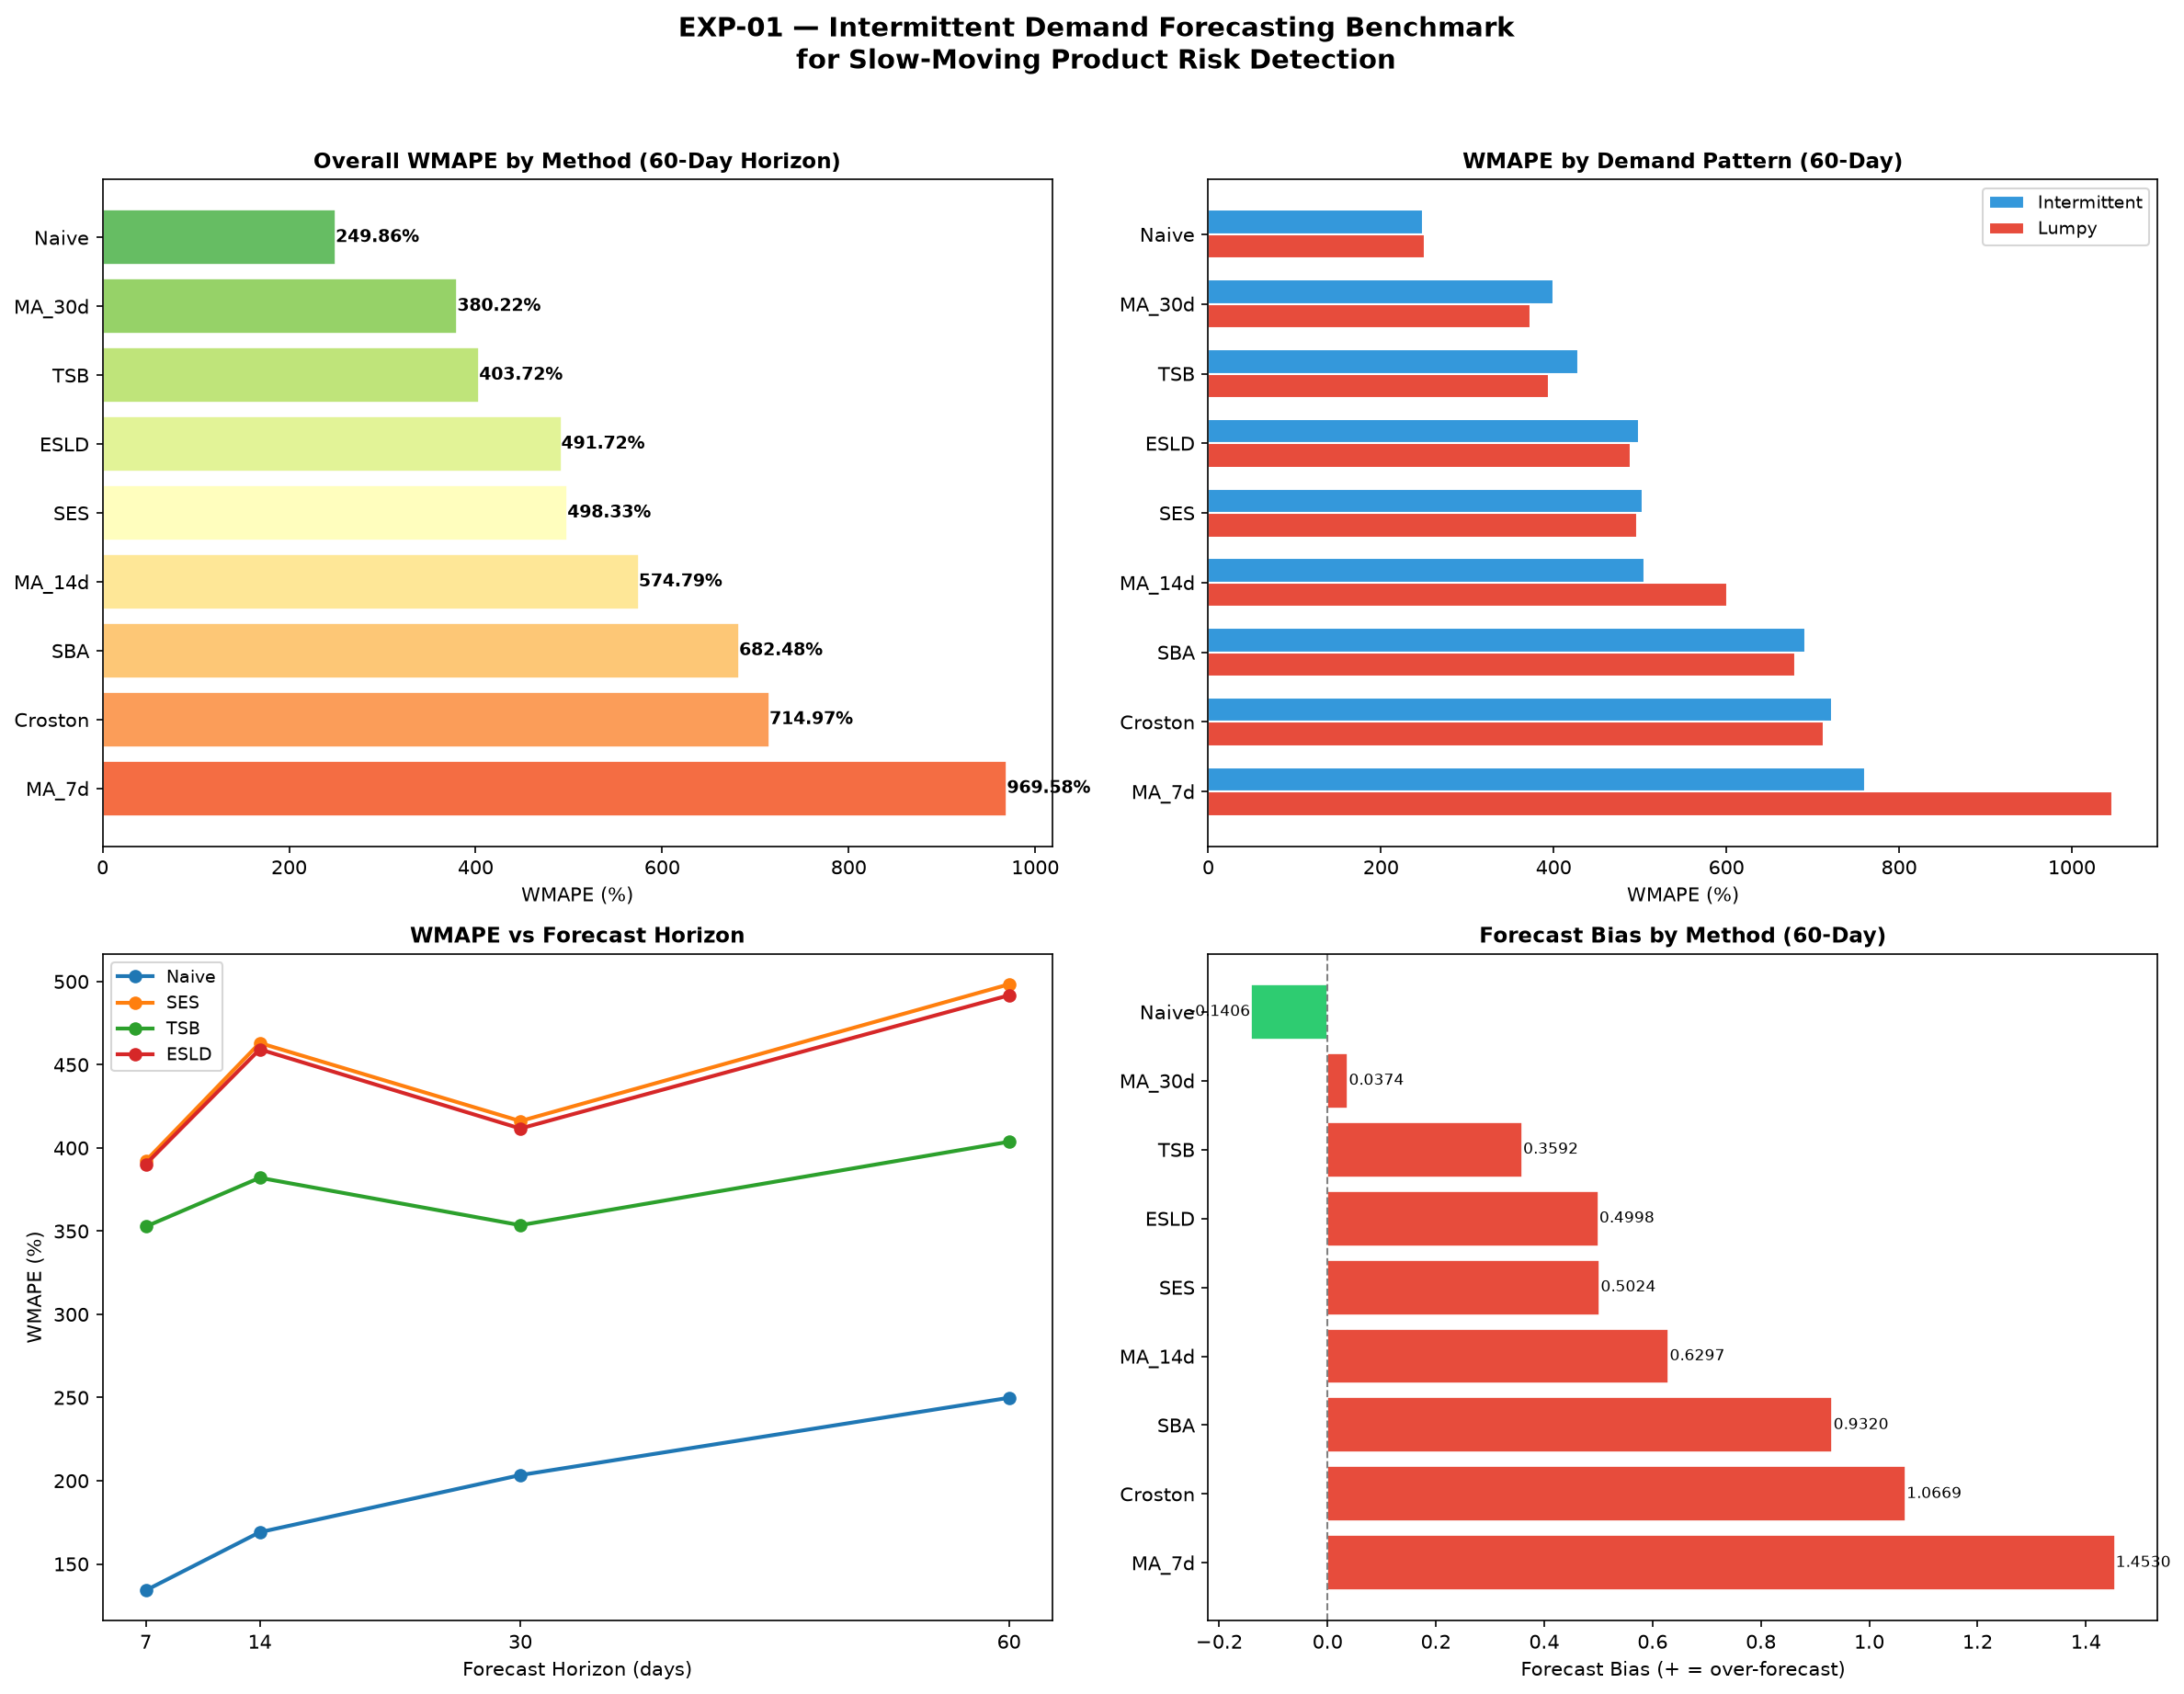

In [7]:
from IPython.display import Image
chart_path = PROJECT_ROOT / 'reports' / 'intermittent_forecast_chart.png'
if chart_path.exists():
    display(Image(filename=str(chart_path), width=900))

## 7. Academic Conclusions

### RQ1 — Forecasting Performance
- **Naive forecast** achieves lowest WMAPE across all horizons due to extreme data sparsity (90.7% zero rate)
- MA-30d and TSB are the top contenders among non-trivial methods
- This is consistent with literature on highly sparse retail demand (Kourentzes 2014)

### RQ2 — Pattern Robustness
- Method rankings are broadly consistent across Intermittent and Lumpy patterns
- Naive dominance holds for both pattern types
- Croston/SBA show higher bias, especially for Lumpy demand

### RQ3 — Contribution to Risk Detection
- Forecast-derived features provide **marginal** improvement to Risk Detection
- High-Risk Recall slightly improves; Macro F1 slightly decreases (feature dilution)
- `demand_probability` (from TSB) is the most informative forecast feature
- Conclusion: Forecasting serves as **supplementary evidence**, not a primary driver